# 01 · Single forward pass: COS vs DICT attention heads

**Requires Apple Silicon + MLX** (`pip install -r requirements-mlx.txt`).

The same airline-passenger data (seaborn `flights`, 1949–1960) is given to
`Llama-3.2-3B-Instruct` in two encodings:

* **COS**: each year mapped to a symbolic bucket (`[-----]` … `[*]` … `[++++++++]`) relative to the median
* **DICT**: the raw Python list of `{'year', 'sum', 'mean'}` records

We run one forward pass with a hand-written decoder block (`attnscope.forward.layer_forward`) so every
head's attention probabilities are available, then compare:

1. the **max over layers** of each head's attention map,
2. an **"average specialization" map**: mean over heads of |head − median head|,
3. a **focused window** that follows each layer's most concentrated head.

The prompts are `prompts/cos.txt` and `prompts/dict.txt`, read with `load_prompt` exactly as in notebook 02.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
import mlx.core as mx
from mlx_lm import load

from attnscope.scope import forward_all_layers, focus_window, most_active_head, load_prompt
from attnscope import plotting

MODEL_ID = "mlx-community/Llama-3.2-3B-Instruct"
FIG_DIR = ROOT / "figures" / "single_pass"
FIG_DIR.mkdir(parents=True, exist_ok=True)

model, tokenizer = load(MODEL_ID)
print(model.args.num_hidden_layers, "layers,", model.args.num_attention_heads, "heads, d_model =", model.args.hidden_size)

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

28 layers, 24 heads, d_model = 3072


In [2]:
texts = {name: load_prompt(ROOT / "prompts" / f"{name}.txt") for name in ("cos", "dict")}

attn, hidden = {}, {}
for name, text in texts.items():
    a, h = forward_all_layers(model, tokenizer, text)
    attn[name] = np.array(a.astype(mx.float32))   # (layers, heads, seq, seq)
    hidden[name] = np.array(h.astype(mx.float32))  # (layers, seq, d_model)
    print(name, "attention", attn[name].shape)

cos attention (28, 24, 306, 306)
dict attention (28, 24, 317, 317)


## Max attention over layers, per head

For each head, take the element-wise max of its attention map across all 28 layers. Heads are labelled
**0-indexed**, so "Head 17" here is the head tracked during generation in notebooks 02–03.

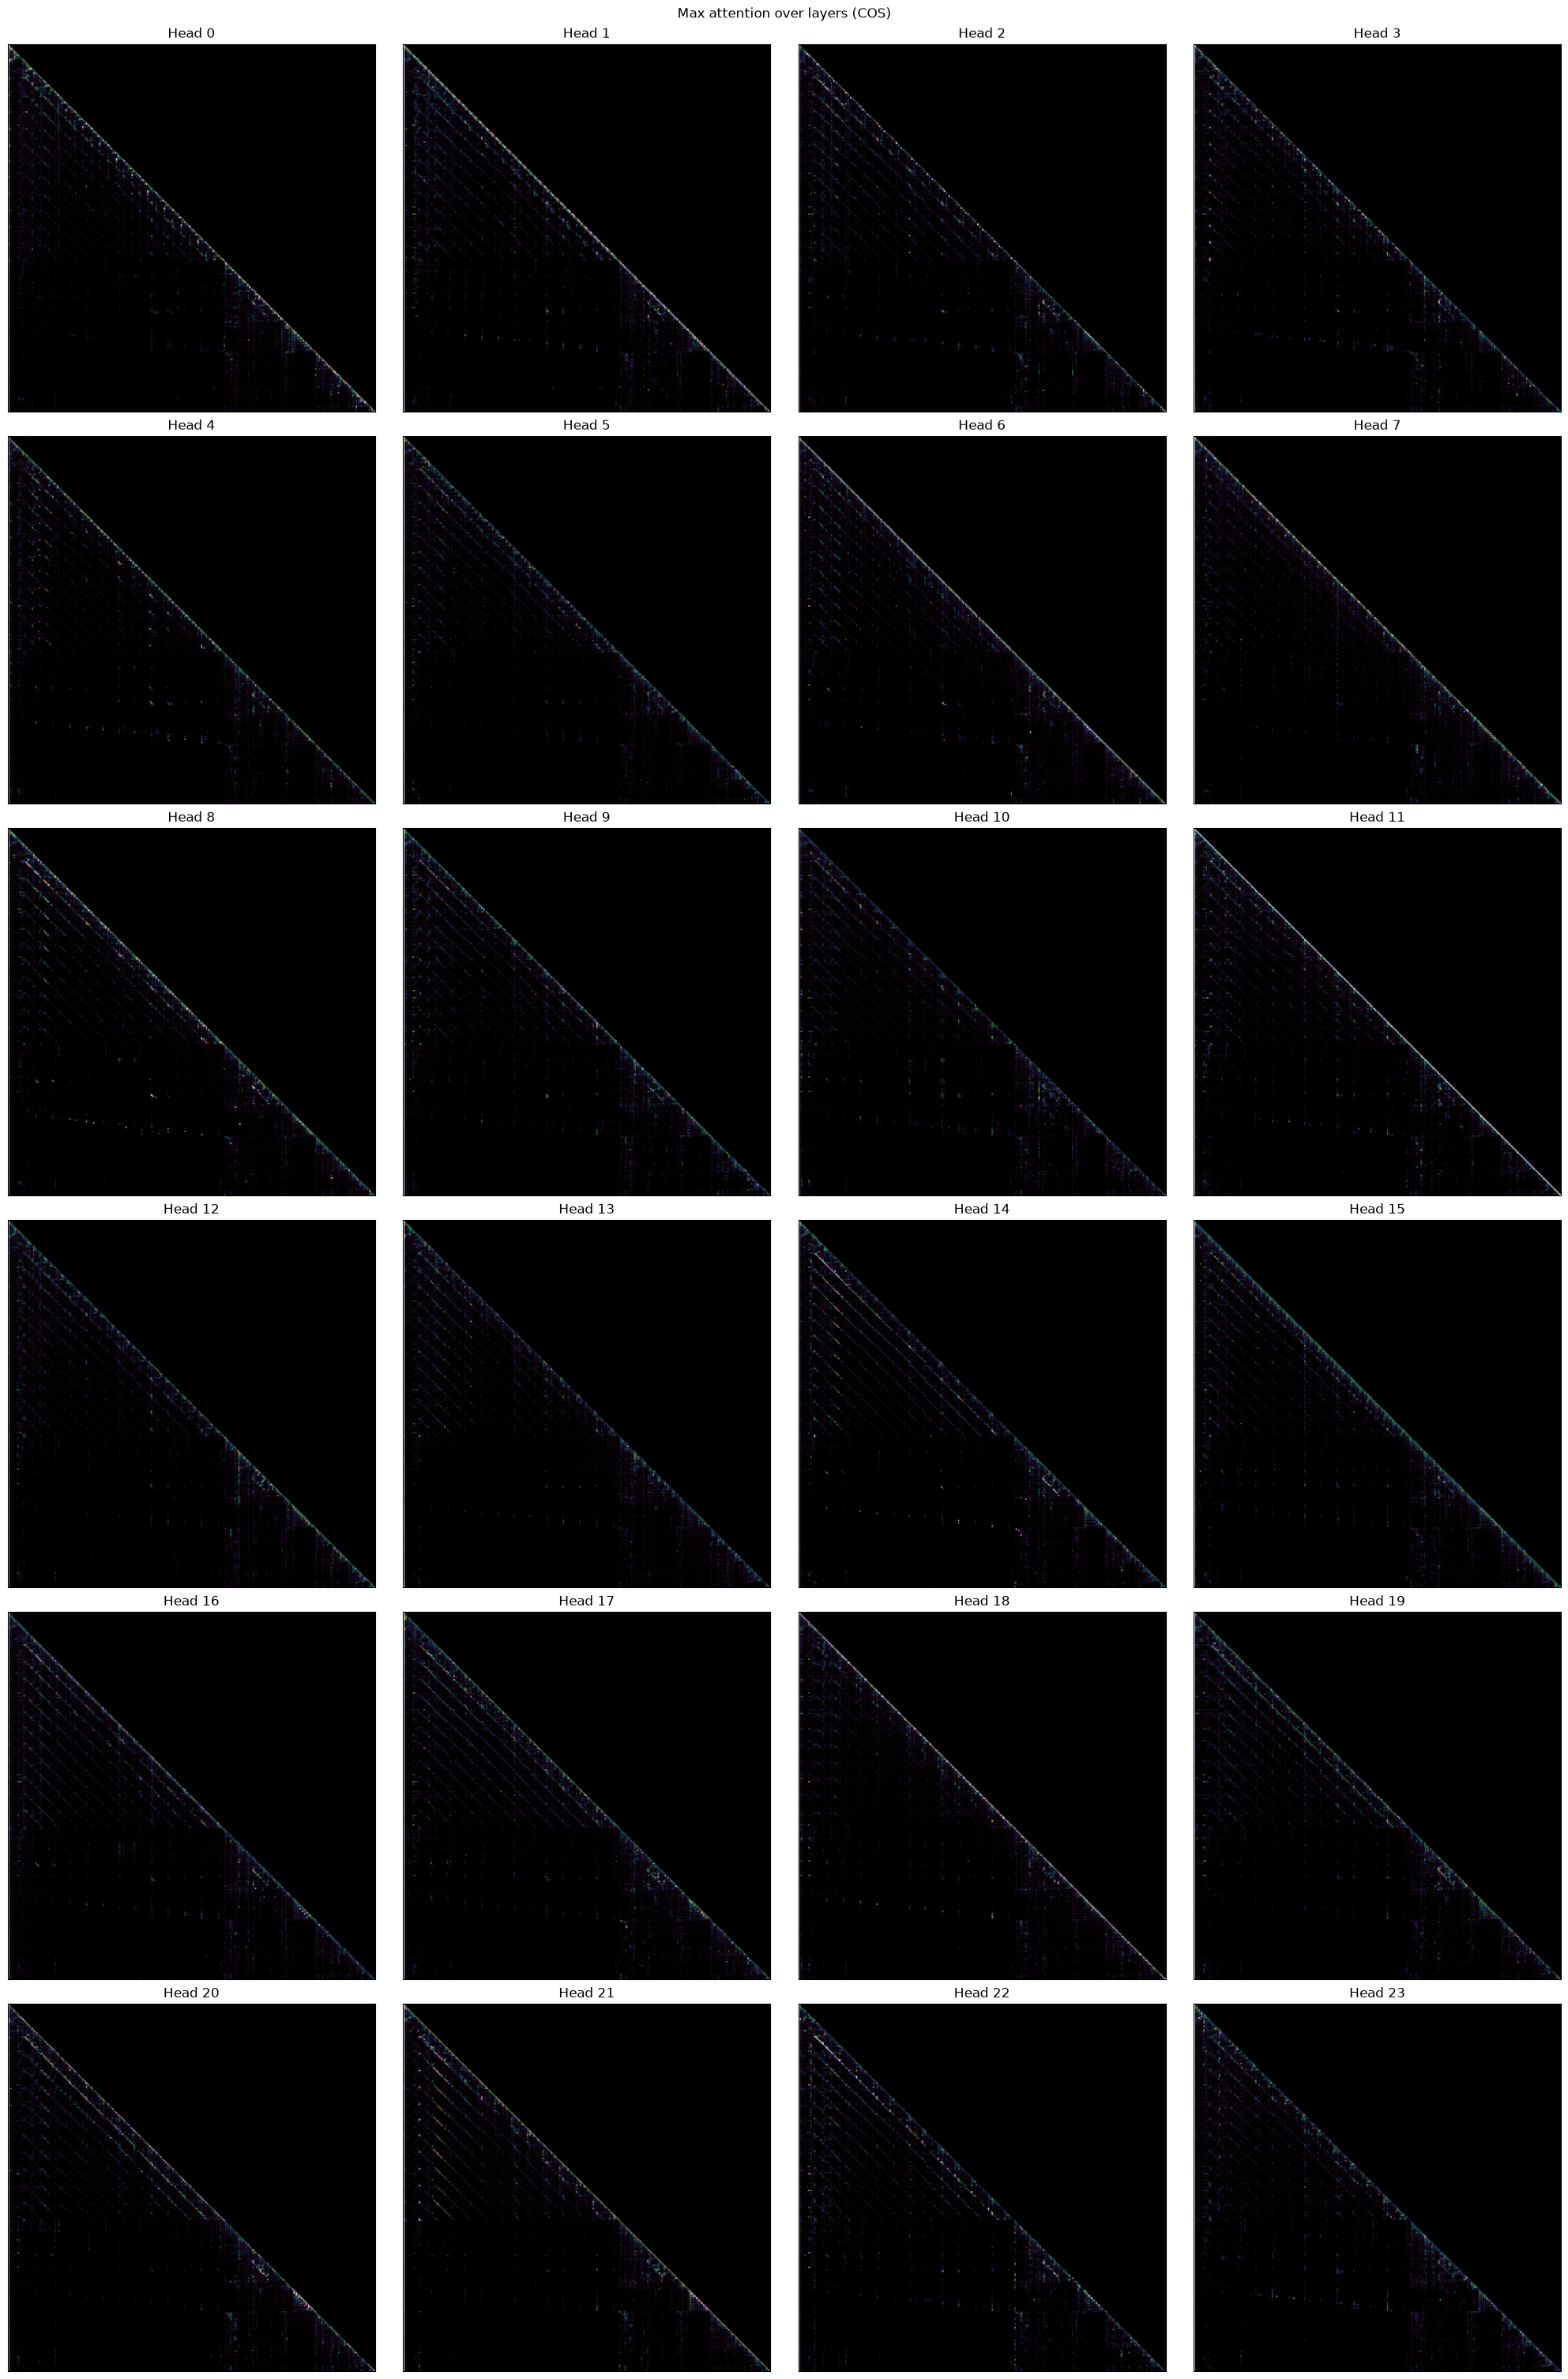

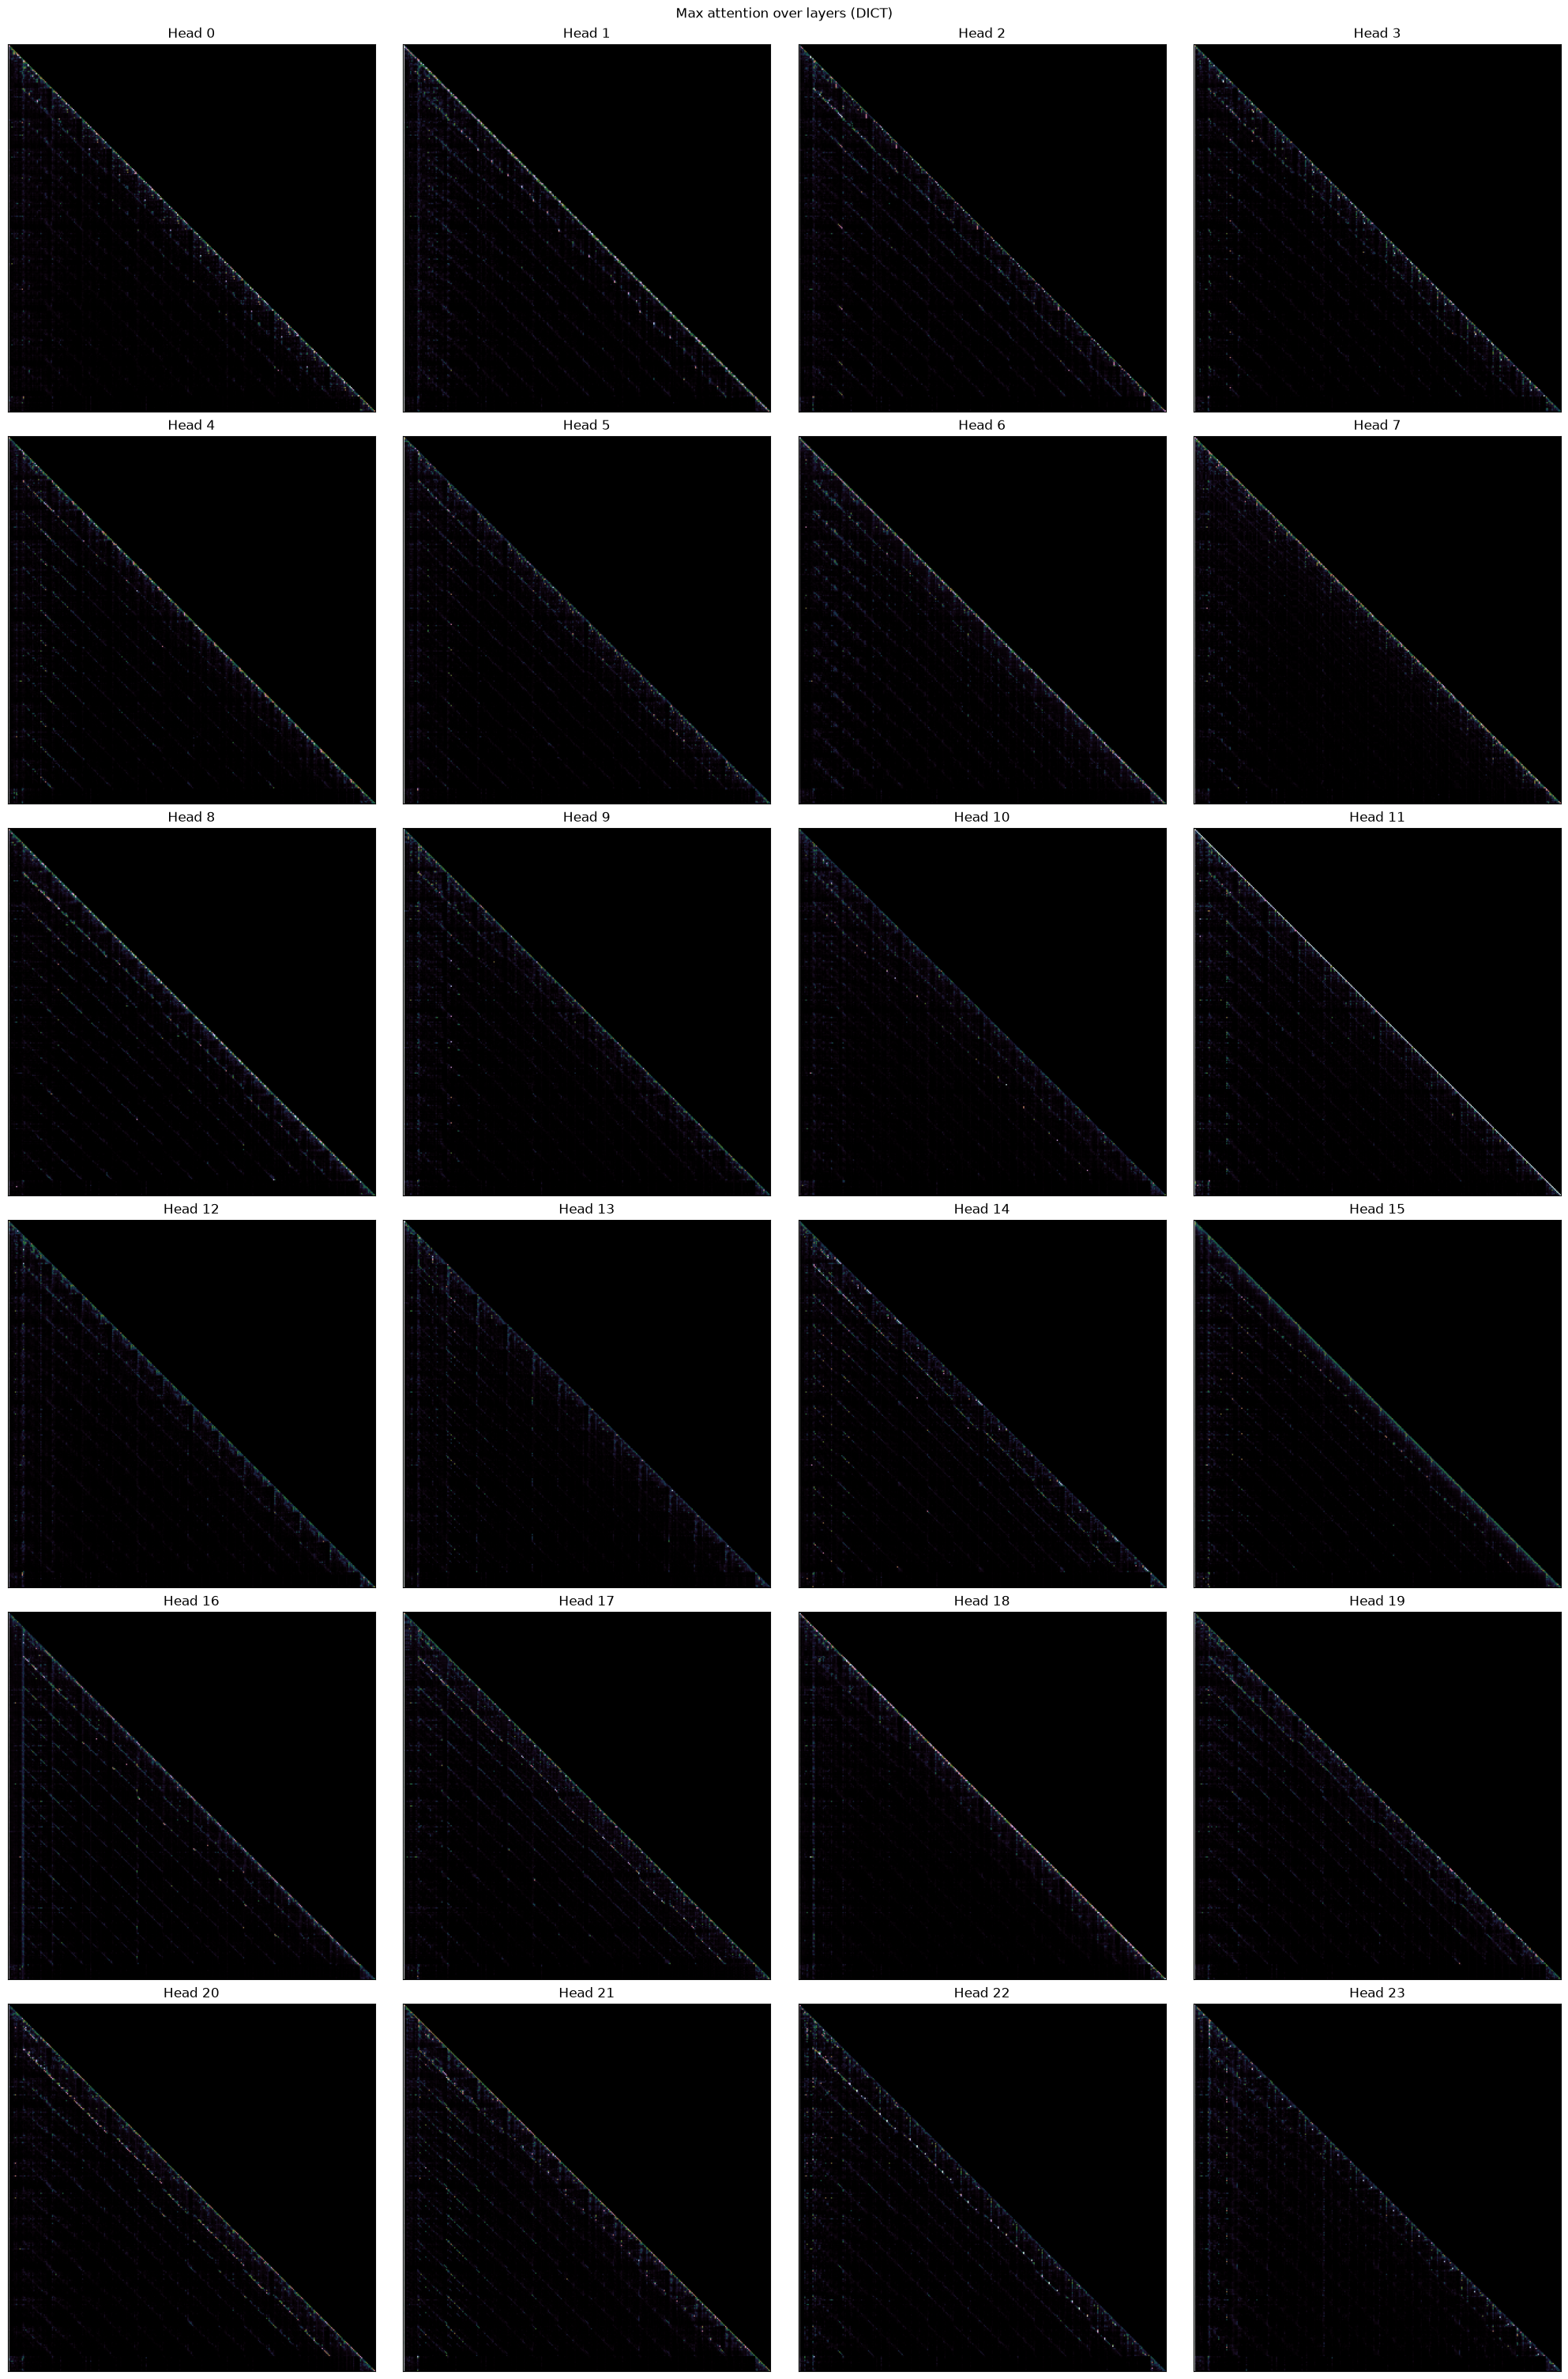

In [3]:
max_heads = {name: a.max(axis=0) for name, a in attn.items()}   # (heads, seq, seq)
for name, m in max_heads.items():
    fig = plotting.head_grid(m, f"Max attention over layers ({name.upper()})")
    fig.savefig(FIG_DIR / f"max_heads_{name}.png", dpi=80)
    plt.show()

## Average specialization

For every (query, key) cell: how far does a typical head deviate from the median head? Bright cells are
positions where heads disagree, i.e. where some heads specialise.

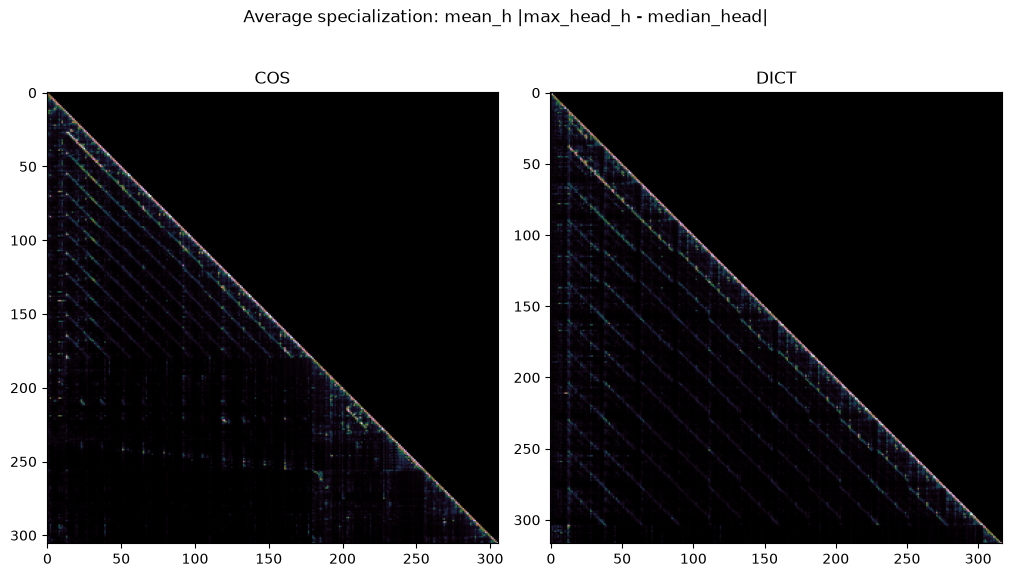

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(10, 6), constrained_layout=True)
for ax, name in zip(axs, ("cos", "dict")):
    ax.imshow(plotting.specialization_map(max_heads[name]), cmap="cubehelix")
    ax.set_title(name.upper())
fig.suptitle("Average specialization: mean_h |max_head_h - median_head|")
fig.savefig(FIG_DIR / "average_specialization.png", dpi=100)
plt.show()

## Focused window on the most concentrated head

For each layer we pick the head whose attention is most concentrated **on the DICT prompt**
(`attnscope.scope.most_active_head`), then crop a 29×29 window around the hottest 3×3-pooled spot of that
same head on each prompt.

In [ ]:
frames = []
for layer in range(model.args.num_hidden_layers):
    head = most_active_head(mx.array(attn["dict"][layer]))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 5))
    for ax, name in ((a1, "cos"), (a2, "dict")):
        window = focus_window(mx.array(attn[name][layer, head]), cam_radius=30)
        ax.imshow(np.array(window), cmap="mako")
        ax.set_title(f"{name.upper()} encoding"); ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f"Layer {layer}  head {head}  (window 29x29)")
    path = FIG_DIR / f"focus_window_layer_{layer:02d}.png"
    fig.savefig(path, dpi=80); plt.close(fig)
    frames.append(path)

plotting.make_gif(frames, FIG_DIR / "focus_window.gif", duration_ms=500)
print("wrote", len(frames), "frames")

wrote 28 frames
